<a href="https://colab.research.google.com/github/rpasquini/herramientas-econometricas/blob/main/Experimentos_Aleatorizados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Inferencia causal y experimentos aleatorizados (RCT)

Este notebook acompaña las slides del Día 5. Ejemplos:

1. **Hospitalización y salud** (EAH 2016): una comparación observacional que *no* identifica un efecto causal.
2. **Seis conductores** y **simulaciones** del libro *Econometrics with Simulations*: conocemos el proceso verdadero, así que podemos ver el sesgo.
3. **Happiness on Tap** (Devoto, Duflo, Dupas, Parienté y Pons, 2012): extracto de un experimento real. Las variables fueron modificadas para el ejercicio, así que **no replican los resultados del paper**.

Plan:
1. Una comparación observacional: hospital y salud
2. Resultados potenciales: seis conductores
3. Sesgo de selección en una simulación
4. Observacional vs. aleatorizado
5. Estimación en un RCT: diferencia de medias y regresión
6. Balance
7. Inferencia por aleatorización (Fisher)
8. Happiness on Tap: análisis completo (balance, primera etapa, ITT, Wald)
9. SUTVA y spillovers
10. Ajuste por covariables (CUPED)
11. Potencia y tamaño de muestra
12. Ejercicios

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from itertools import combinations
from scipy import stats
from statsmodels.stats.power import TTestIndPower

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25})
rng = np.random.default_rng(2026)

def smd(a, b):
    "Diferencia estandarizada de medias"
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

/home/rpasquini/miniconda3/envs/econometrics-book-v2/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## 1. Una comparación observacional: ¿pasar por el hospital mejora la salud?

Encuesta Anual de Hogares de CABA 2016: `s8` indica si la persona estuvo internada en el último año y `sn16` es la salud autopercibida, que codificamos de 0 (muy mala) a 5 (excelente).

In [2]:
base = 'https://raw.githubusercontent.com/rpasquini/herramientas-econometricas/main/datos/'
e = pd.read_csv(base + 'eah2016_individual.csv')
sal = {'Excelente': 5, 'Muy bueno': 4, 'Bueno': 3, 'Regular': 2, 'Malo': 1, 'Muy malo': 0}
e = e[e['s8'].isin([1, 2]) & e['sn16'].isin(sal)].copy()
e['salud'] = e['sn16'].map(sal)
e['hosp'] = (e['s8'] == 1).astype(int)
e['mujer'] = (e['sexo'] == 'mujer').astype(int)
print(len(e))
e.groupby('hosp')['salud'].agg(['count', 'mean', 'std'])

14508


,count,mean,std
hosp,,,
0,13338,3.672065,0.942511
1,1170,3.022222,1.111193


In [3]:
r0 = smf.ols('salud ~ hosp', e).fit(cov_type='HC1')
r1 = smf.ols('salud ~ hosp + edad + mujer + aesc', e).fit(cov_type='HC1')
pd.DataFrame({'Sin controles': [r0.params['hosp'], r0.bse['hosp']],
              'Con controles': [r1.params['hosp'], r1.bse['hosp']]}, index=['coef. hosp', 'EE robusto']).round(3)

,Sin controles,Con controles
coef. hosp,-0.650,-0.514
EE robusto,0.033,0.030


Los hospitalizados están **peor**. ¿Es un efecto causal del hospital? Miremos si los grupos eran comparables en lo observable:

In [4]:
h1, h0 = e[e.hosp == 1], e[e.hosp == 0]
pd.DataFrame({'Hospitalizados': h1[['edad', 'mujer', 'aesc']].mean(),
              'No hospitalizados': h0[['edad', 'mujer', 'aesc']].mean(),
              'Dif. estandarizada': [smd(h1[c], h0[c]) for c in ['edad', 'mujer', 'aesc']]}).round(3)

,Hospitalizados,No hospitalizados,Dif. estandarizada
edad,45.599,37.866,0.320
mujer,0.603,0.522,0.164
aesc,10.917,10.926,-0.001


Los hospitalizados son bastante mayores. Controlar por edad, sexo y escolaridad reduce la brecha, pero no la elimina: hay factores que no observamos (gravedad previa, enfermedades crónicas) que determinan *quién* se interna y cómo está de salud.

Más datos no resuelven esto: el problema es de **identificación**, no de precisión.

## 2. Resultados potenciales: seis conductores

Para cada persona existen dos resultados potenciales, $Y_i(0)$ e $Y_i(1)$. Acá los conocemos (algo que nunca ocurre con datos reales) para ver qué estima cada comparación.

In [5]:
po = pd.DataFrame({'Y0': [480, 520, 610, 450, 500, 430],
                   'Y1': [560, 590, 700, 500, 560, 520]}, index=range(1, 7))
po['tau'] = po['Y1'] - po['Y0']
po['T'] = [1, 1, 1, 0, 0, 0]
po['Y'] = np.where(po['T'] == 1, po['Y1'], po['Y0'])
po

,Y0,Y1,tau,T,Y
1,480,560,80,1,560
2,520,590,70,1,590
3,610,700,90,1,700
4,450,500,50,0,450
5,500,560,60,0,500
6,430,520,90,0,430


In [6]:
ATE = po['tau'].mean()
ATT = po.loc[po['T'] == 1, 'tau'].mean()
naive = po.loc[po['T'] == 1, 'Y'].mean() - po.loc[po['T'] == 0, 'Y'].mean()
sesgo = po.loc[po['T'] == 1, 'Y0'].mean() - po.loc[po['T'] == 0, 'Y0'].mean()
print(f'ATE = {ATE:.1f}   ATT = {ATT:.1f}')
print(f'naive = {naive:.1f}')
print(f'sesgo de selección = {sesgo:.1f}')
print(f'ATT + sesgo = {ATT + sesgo:.1f}  (coincide con naive)')

ATE = 73.3   ATT = 80.0
naive = 156.7
sesgo de selección = 76.7
ATT + sesgo = 156.7  (coincide con naive)


Ahora supongamos que el tratamiento se **sortea**: elegimos al azar 3 de los 6 conductores. Hay $\binom{6}{3}=20$ asignaciones posibles, y las podemos enumerar todas.

Promedio de las 20 estimaciones: 73.33   (ATE = 73.33)
Mínimo -16.7, máximo 163.3


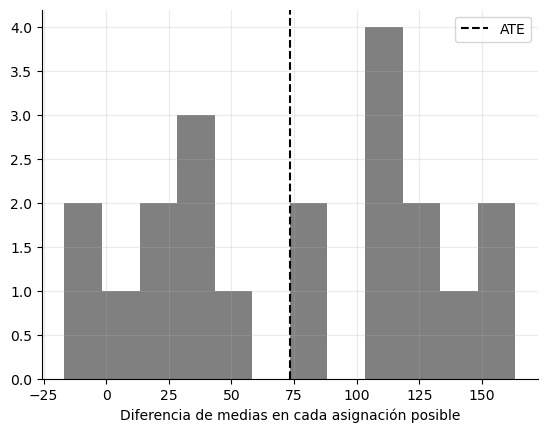

In [7]:
difs = []
for tratados in combinations(range(6), 3):
    T = np.zeros(6, bool); T[list(tratados)] = True
    Y = np.where(T, po['Y1'].values, po['Y0'].values)
    difs.append(Y[T].mean() - Y[~T].mean())
difs = np.array(difs)
print(f'Promedio de las 20 estimaciones: {difs.mean():.2f}   (ATE = {ATE:.2f})')
print(f'Mínimo {difs.min():.1f}, máximo {difs.max():.1f}')
plt.hist(difs, bins=12, color='grey'); plt.axvline(ATE, color='k', ls='--', label='ATE')
plt.xlabel('Diferencia de medias en cada asignación posible'); plt.legend(); plt.show()

Con aleatorización el estimador es **insesgado**: su promedio sobre todas las asignaciones posibles es el ATE. En cada experimento puntual hay error (la dispersión), pero no hay sesgo sistemático.

## 3. Sesgo de selección en una simulación

Proceso generador del libro (dashboard `selection_bias`): cada conductor tiene una motivación $m_i\sim N(0,1)$; $Y_i(0)=500+30\gamma m_i+\varepsilon_i$ con $\varepsilon_i\sim N(0,50^2)$; $Y_i(1)=Y_i(0)+\delta$. Con participación voluntaria se trata quien tiene $m_i>0$. El parámetro $\gamma$ es la **intensidad de la selección**.

In [8]:
def simular(n, delta, gamma, modo='observacional', rng=rng):
    m = rng.normal(0, 1, n)
    Y0 = 500 + 30 * gamma * m + rng.normal(0, 50, n)
    Y1 = Y0 + delta
    T = (m > 0).astype(int) if modo == 'observacional' else rng.permutation(np.r_[np.ones(n // 2), np.zeros(n - n // 2)]).astype(int)
    Y = np.where(T == 1, Y1, Y0)
    return pd.DataFrame({'m': m, 'T': T, 'Y': Y, 'Y0': Y0, 'Y1': Y1})

def naive(d): return d.loc[d['T'] == 1, 'Y'].mean() - d.loc[d['T'] == 0, 'Y'].mean()

filas = []
for gamma in [0, 1, 2, 3]:
    for n in [100, 500, 2000]:
        d = simular(n, 0, gamma)
        filas.append({'gamma': gamma, 'n': n, 'naive (delta = 0)': naive(d)})
pd.DataFrame(filas).pivot(index='gamma', columns='n', values='naive (delta = 0)').round(1)

n,100,500,2000
gamma,,,
0,-13.0,10.0,-1.7
1,53.6,52.4,51.8
2,108.5,100.8,92.2
3,160.0,145.8,143.6


El programa **no tiene ningún efecto** ($\delta=0$), pero la comparación naive da un valor positivo que crece con $\gamma$ y **no desaparece con $n$**: más datos dan una estimación más precisa del número equivocado. Con $\gamma=3$ el sesgo es cercano a $30\gamma\,(E[m\mid m>0]-E[m\mid m<0])\approx 30\cdot3\cdot1{,}6\approx 144$.

Descomposición para una muestra: naive = efecto verdadero + sesgo de selección.

In [9]:
d = simular(2000, 100, 3)
dif_naive = naive(d)
efecto = (d['Y1'] - d['Y0']).loc[d['T'] == 1].mean()          # ATT
sesgo = d.loc[d['T'] == 1, 'Y0'].mean() - d.loc[d['T'] == 0, 'Y0'].mean()
print(f'naive = {dif_naive:.1f} = ATT {efecto:.1f} + sesgo {sesgo:.1f}')

naive = 241.6 = ATT 100.0 + sesgo 141.6


## 4. Observacional vs. aleatorizado

Repetimos el experimento 500 veces en cada modo de asignación, con $\delta=0$ y $\gamma=3$.

Observacional: media 143.8, desvío 8.4
Aleatorizado : media 0.7, desvío 12.2


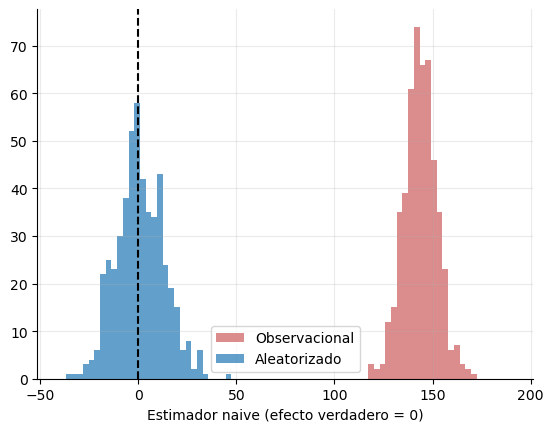

In [10]:
def repetir(modo, n=300, delta=0, gamma=3, B=500):
    return np.array([naive(simular(n, delta, gamma, modo)) for _ in range(B)])

obs, ale = repetir('observacional'), repetir('aleatorizado')
print(f'Observacional: media {obs.mean():.1f}, desvío {obs.std():.1f}')
print(f'Aleatorizado : media {ale.mean():.1f}, desvío {ale.std():.1f}')
bins = np.linspace(-40, 190, 80)
plt.hist(obs, bins=bins, alpha=.7, color='indianred', label='Observacional')
plt.hist(ale, bins=bins, alpha=.7, color='tab:blue', label='Aleatorizado')
plt.axvline(0, color='k', ls='--'); plt.xlabel('Estimador naive (efecto verdadero = 0)'); plt.legend(); plt.show()

La aleatorización elimina el sesgo **independientemente de $\gamma$**. Veámoslo en el balance de la motivación (que, en la práctica, podría no ser observable):

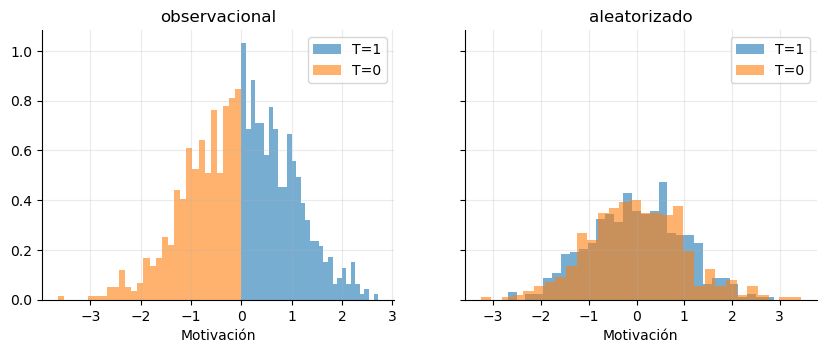

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, modo in zip(axs, ['observacional', 'aleatorizado']):
    d = simular(1000, 0, 3, modo)
    ax.hist(d.loc[d['T'] == 1, 'm'], bins=30, alpha=.6, label='T=1', density=True)
    ax.hist(d.loc[d['T'] == 0, 'm'], bins=30, alpha=.6, label='T=0', density=True)
    ax.set_title(modo); ax.set_xlabel('Motivación'); ax.legend()
plt.show()

Observación: la aleatorización **no reduce la variabilidad** (el desvío del estimador aleatorizado no es menor). Es insesgado, no necesariamente preciso.

¿Qué cambia si $\delta=200$ y la selección es fuerte? Probá distintos parámetros y verificá que en el modo aleatorizado el estimador se centra en $\delta$ para cualquier $\gamma$:

In [12]:
for gamma in [0, 1, 3]:
    print(gamma, repetir('aleatorizado', n=300, delta=200, gamma=gamma, B=300).mean().round(1))

0 200.4
1 200.2
3 199.9


## 5. Estimación en un RCT: diferencia de medias y regresión

Con asignación aleatoria el efecto se estima comparando promedios. Tres formas equivalentes de hacerlo, sobre una muestra aleatorizada con $\delta=100$:

In [13]:
d = simular(400, 100, 3, 'aleatorizado')
y1, y0 = d.loc[d['T'] == 1, 'Y'], d.loc[d['T'] == 0, 'Y']
print('Diferencia de medias:', round(y1.mean() - y0.mean(), 2))
print('Test t (Welch):', stats.ttest_ind(y1, y0, equal_var=False))
r = smf.ols('Y ~ T', d).fit(cov_type='HC1')
r.summary().tables[1]

Diferencia de medias: 101.96
Test t (Welch): TtestResult(statistic=np.float64(9.949476012715321), pvalue=np.float64(5.680870284953331e-21), df=np.float64(397.3353802452558))


,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,506.3572,7.097,71.351,0.000,492.448,520.266
T,101.9625,10.248,9.949,0.000,81.877,122.048


El coeficiente de `T` es exactamente la diferencia de medias, y con errores robustos el estadístico es prácticamente el del test de Welch. Bajo aleatorización, $T\perp\varepsilon$ **por diseño**.

**Agregar una covariable pre-tratamiento** no cambia el valor esperado del estimador, pero sí su precisión (sección 10).

## 6. Balance

Cargamos el extracto de *Happiness on Tap*: una promoción aleatoria de conexiones domiciliarias de agua en Tetuán (Marruecos).

- `motivacion`: 1 si el hogar recibió la promoción (asignación aleatoria)
- `conectado`: 1 si el hogar se conectó a la red
- `sexojefe` (1/2), `edadjefe`, `jefesabeleer`, `jefesabeescribir`: características del jefe/a de hogar
- `pdiasfueaescuela`: porcentaje de días que los hijos fueron a la escuela (solo hogares con hijos en edad escolar)

*(En el extracto `sexojefe` toma valores 1 y 2; asumimos 2 = mujer.)*

In [14]:
url = 'https://raw.githubusercontent.com/rpasquini/econometrics_and_causality/master/happiness_on_tap_extract.csv'
d = pd.read_csv(url)
d['mujerjefe'] = (d['sexojefe'] == 2).astype(int)
d['T'] = d['motivacion']
print(d.shape)
d.groupby('T').size()

(788, 10)


T
0    377
1    411
dtype: int64

In [15]:
covs = ['mujerjefe', 'edadjefe', 'jefesabeleer', 'jefesabeescribir']
t1, t0 = d[d['T'] == 1], d[d['T'] == 0]
bal = pd.DataFrame({'Tratamiento': t1[covs].mean(), 'Control': t0[covs].mean()})
bal['Diferencia'] = bal['Tratamiento'] - bal['Control']
bal['p-valor'] = [stats.ttest_ind(t1[c].dropna(), t0[c].dropna(), equal_var=False).pvalue for c in covs]
bal['Dif. estandarizada'] = [smd(t1[c].dropna(), t0[c].dropna()) for c in covs]
bal.round(3)

,Tratamiento,Control,Diferencia,p-valor,Dif. estandarizada
mujerjefe,0.221,0.249,-0.028,0.357,-0.066
edadjefe,51.081,51.664,-0.583,0.572,-0.041
jefesabeleer,0.609,0.605,0.004,0.908,0.008
jefesabeescribir,0.592,0.589,0.003,0.935,0.006


In [16]:
# Test conjunto: regresión de T sobre las covariables, H0: todos los coeficientes = 0
dc = d.dropna(subset=covs)
fj = smf.ols('T ~ ' + ' + '.join(covs), dc).fit()
print(f'F = {fj.fvalue:.2f}, p = {fj.f_pvalue:.2f}')

F = 0.34, p = 0.85


Ninguna diferencia es significativa y el test conjunto no rechaza: la aleatorización produjo grupos comparables en lo observable. Compará con el desbalance entre hospitalizados y no hospitalizados (sección 1).

*Nota:* con muchas covariables esperamos algún falso positivo por azar (con 20 covariables, una diferencia significativa al 5% no es una señal de alarma).

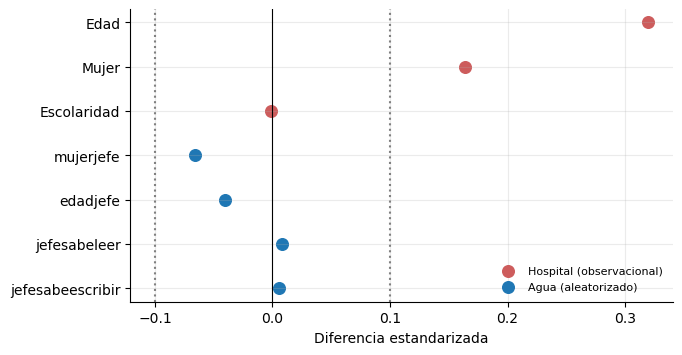

In [17]:
# Love plot: balance observacional (hospital) vs. experimental (agua)
smd_h = {'Edad': smd(h1.edad, h0.edad), 'Mujer': smd(h1.mujer, h0.mujer), 'Escolaridad': smd(h1.aesc, h0.aesc)}
smd_m = {c: smd(t1[c].dropna(), t0[c].dropna()) for c in covs}
fig, ax = plt.subplots(figsize=(7, 3.8))
ys = np.arange(len(smd_h) + len(smd_m))[::-1]
ax.scatter(list(smd_h.values()), ys[:3], color='indianred', s=70, label='Hospital (observacional)')
ax.scatter(list(smd_m.values()), ys[3:], color='tab:blue', s=70, label='Agua (aleatorizado)')
ax.set_yticks(ys); ax.set_yticklabels(list(smd_h) + list(smd_m))
for x in (-.1, .1): ax.axvline(x, color='grey', ls=':')
ax.axvline(0, color='k', lw=.8); ax.set_xlabel('Diferencia estandarizada'); ax.legend(frameon=False, loc='lower right', fontsize=8)
plt.show()

## 7. Inferencia por aleatorización (Fisher)

Con la hipótesis nula *sharp* ($\tau_i=0$ para todos) conocemos ambos resultados potenciales de cada unidad. Podemos entonces **rehacer el sorteo** y ver qué tan extremo es el estadístico observado. Primero, un ejemplo de juguete: diez provincias, 5 reciben un programa; entre las tratadas 4 mejoran, entre las controles ninguna.

In [18]:
Y = np.array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0]); T = np.array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0])
obs = Y[T == 1].mean() - Y[T == 0].mean()
dif = []
for c in combinations(range(10), 5):
    m = np.zeros(10, bool); m[list(c)] = True
    dif.append(Y[m].mean() - Y[~m].mean())
dif = np.array(dif)
print('Diferencia observada:', obs, ' asignaciones posibles:', len(dif))
print('p unilateral:', np.mean(dif >= obs - 1e-9).round(3), ' p bilateral:', np.mean(np.abs(dif) >= abs(obs) - 1e-9).round(3))
print('Test t de diferencia de medias, p =', stats.ttest_ind(Y[T == 1], Y[T == 0]).pvalue.round(3))

Diferencia observada: 0.8  asignaciones posibles: 252
p unilateral: 0.024  p bilateral: 0.048
Test t de diferencia de medias, p = 0.004


Con muestras tan chicas el test $t$ **sobrerrechaza** (p = 0,004) mientras que el p-valor exacto de Fisher es 0,048.

Ahora la versión Monte Carlo (10.000 reasignaciones) cuando hay demasiadas asignaciones para enumerarlas. La usamos en la sección siguiente.

In [19]:
def fisher(y, t, B=10000, rng=np.random.default_rng(1)):
    obs = y[t == 1].mean() - y[t == 0].mean()
    perm = np.empty(B)
    for k in range(B):
        s = rng.permutation(t); perm[k] = y[s == 1].mean() - y[s == 0].mean()
    return obs, perm, np.mean(np.abs(perm) >= abs(obs))

## 8. Happiness on Tap: análisis completo

### 8.1 Primera etapa: la promoción y la conexión

El sorteo asigna la **promoción**, no la conexión: el cumplimiento es imperfecto.

In [20]:
print(pd.crosstab(d['T'], d['conectado'], normalize='index').round(3))
pe = smf.ols('conectado ~ T', d).fit(cov_type='HC1')
print(pe.summary().tables[1])

conectado      0      1
T                      
0          0.897  0.103
1          0.299  0.701
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1034      0.016      6.587      0.000       0.073       0.134
T              0.5973      0.028     21.692      0.000       0.543       0.651


### 8.2 Efecto sobre la asistencia escolar (ITT)

Regresión de `pdiasfueaescuela` sobre la asignación. Como la asignación es aleatoria, el coeficiente es el efecto *de la promoción* (ITT) y tiene interpretación causal, sin y con covariables pre-tratamiento.

In [21]:
dd = d.dropna(subset=['pdiasfueaescuela']).copy()          # n = 320
dd2 = dd.dropna(subset=covs)                                 # n = 317 (3 hogares sin datos de covariables)
i0 = smf.ols('pdiasfueaescuela ~ T', dd).fit(cov_type='HC1')
i1 = smf.ols('pdiasfueaescuela ~ T + ' + ' + '.join(covs), dd2).fit(cov_type='HC1')
res = pd.DataFrame({'Sin controles': [i0.params['T'], i0.bse['T'], i0.pvalues['T']],
                    'Con controles': [i1.params['T'], i1.bse['T'], i1.pvalues['T']]}, index=['ITT', 'EE robusto', 'p-valor'])
print('n =', len(dd), '(sin controles),', len(dd2), '(con controles)  media control =', dd.loc[dd['T'] == 0, 'pdiasfueaescuela'].mean().round(1))
res.round(3)

n = 320 (sin controles), 317 (con controles)  media control = 62.2


,Sin controles,Con controles
ITT,-4.641,-4.104
EE robusto,2.854,2.889
p-valor,0.104,0.155


El efecto estimado es **impreciso**: el intervalo de confianza incluye cero y valores de varios puntos porcentuales de cualquier signo. Con este error estándar el efecto mínimo detectable (80% de potencia) es aproximadamente $2{,}8\times EE$.

In [22]:
ci = i0.conf_int().loc['T']
print('IC 95%:', ci.round(1).tolist(), ' EMD (80% potencia) ~', round(2.8 * i0.bse['T'], 1), 'p.p.')

IC 95%: [-10.2, 1.0]  EMD (80% potencia) ~ 8.0 p.p.


### 8.3 Inferencia por aleatorización y *attrition*

Diferencia observada = -4.64   p Fisher = 0.113   p test t = 0.105


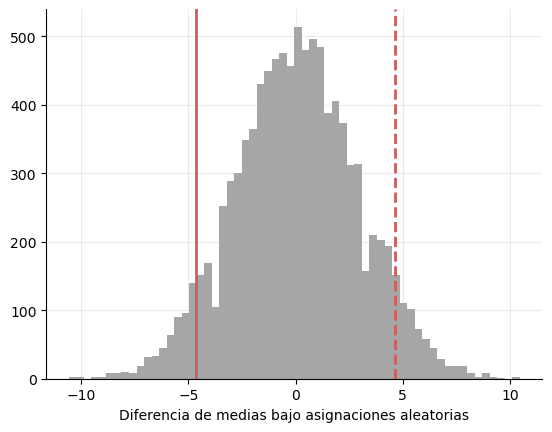

In [23]:
y, t = dd['pdiasfueaescuela'].values, dd['T'].values
obs, perm, p_f = fisher(y, t)
print(f'Diferencia observada = {obs:.2f}   p Fisher = {p_f:.3f}   p test t = {stats.ttest_ind(y[t==1], y[t==0], equal_var=False).pvalue:.3f}')
plt.hist(perm, bins=60, color='grey', alpha=.7)
plt.axvline(obs, color='indianred', lw=2); plt.axvline(-obs, color='indianred', lw=2, ls='--')
plt.xlabel('Diferencia de medias bajo asignaciones aleatorias'); plt.show()

In [24]:
# Attrition: ¿el resultado se observa con la misma frecuencia en ambos brazos?
d['resp'] = d['pdiasfueaescuela'].notna().astype(int)
print(d.groupby('T')['resp'].mean().round(3))
print(smf.ols('resp ~ T', d).fit(cov_type='HC1').summary().tables[1])

T
0    0.390
1    0.421
Name: resp, dtype: float64
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.3899      0.025     15.503      0.000       0.341       0.439
T              0.0310      0.035      0.885      0.376      -0.038       0.100


### 8.4 De la asignación al tratamiento recibido (Wald)

Si el único canal fuera la conexión efectiva (*restricción de exclusión*), el efecto de conectarse para los hogares que se conectan por la promoción es $ITT/\hat\pi$, con $\hat\pi$ la primera etapa. Es el estimador de **variables instrumentales** (Día 8).

In [25]:
wald = i0.params['T'] / pe.params['T']
print(f'ITT = {i0.params["T"]:.2f},  primera etapa = {pe.params["T"]:.3f},  Wald = {wald:.2f}')
# Comparar con la comparación naive conectados vs. no conectados (incorpora auto-selección):
print(dd.groupby('conectado')['pdiasfueaescuela'].mean().round(2))

ITT = -4.64,  primera etapa = 0.597,  Wald = -7.77
conectado
0    61.69
1    57.83
Name: pdiasfueaescuela, dtype: float64


**No** hay que comparar directamente conectados vs. no conectados: esa comparación reintroduce la auto-selección. El sorteo identifica el efecto de la *asignación* y, con supuestos adicionales, el de la conexión.

## 9. SUTVA y spillovers

SUTVA exige que el resultado de una unidad dependa solo de su propio tratamiento. Supongamos mercados con 10 conductores y **100 viajes fijos** que se reparten; los tratados atraen el doble de viajes. El efecto verdadero sobre el *mercado* es cero (los viajes solo se redistribuyen).

Aleatorización individual: 6.72   por mercado: 0.14   (efecto verdadero sobre el mercado = 0)


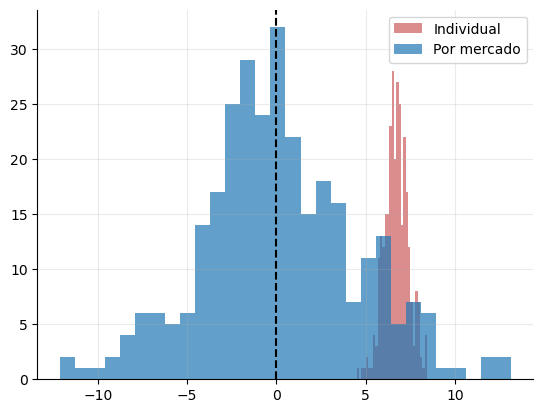

In [26]:
def mercados(individual, nmk=200, k=10, viajes=100, boost=2.0, rng=rng):
    yt, yc = [], []
    for _ in range(nmk):
        fx = rng.normal(0, 30)
        if individual: T = rng.permutation(np.r_[np.ones(k // 2), np.zeros(k - k // 2)])
        else: T = np.full(k, float(rng.random() < .5))
        w = np.where(T == 1, boost, 1.0)
        y = 500 + viajes * w / w.sum() + rng.normal(0, 15, k) + (0 if individual else fx)
        yt += list(y[T == 1]); yc += list(y[T == 0])
    return np.mean(yt) - np.mean(yc) if yt and yc else np.nan

ind = np.array([mercados(True) for _ in range(300)])
clu = np.array([mercados(False) for _ in range(300)])
print(f'Aleatorización individual: {np.nanmean(ind):.2f}   por mercado: {np.nanmean(clu):.2f}   (efecto verdadero sobre el mercado = 0)')
plt.hist(ind, bins=30, alpha=.7, color='indianred', label='Individual')
plt.hist(clu[~np.isnan(clu)], bins=30, alpha=.7, color='tab:blue', label='Por mercado')
plt.axvline(0, color='k', ls='--'); plt.legend(); plt.show()

Con aleatorización individual el estimador mide el *spillover* (ganancia de los tratados a costa de los controles), no el efecto sobre el mercado. Aleatorizar por mercado lo corrige, a costa de menos unidades de aleatorización (más varianza).

## 10. Ajuste por covariables (CUPED / ANCOVA)

Agregar una covariable pre-tratamiento $X$ no cambia $E[\hat\delta]$, pero reduce su varianza en un factor $\approx 1-R^2_{Y|X}$. Simulamos con $R^2=0{,}5$.

Media (sin X, con X): [50.  50.1]
Desvío (sin X, con X): [8.4 5.9]  cociente de varianzas: 2.02  vs 1/(1-R2) = 2


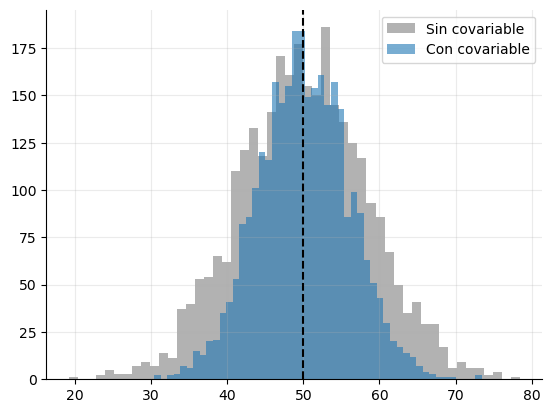

In [27]:
def una_vez(n=200, delta=50, sig=60, R2=.5, rng=rng):
    x = rng.normal(size=n); u = rng.normal(size=n)
    y0 = 500 + sig * (np.sqrt(R2) * x + np.sqrt(1 - R2) * u)
    T = rng.permutation(np.r_[np.ones(n // 2), np.zeros(n // 2)])
    y = y0 + delta * T
    b0 = y[T == 1].mean() - y[T == 0].mean()
    b1 = np.linalg.lstsq(np.column_stack([np.ones(n), T, x]), y, rcond=None)[0][1]
    return b0, b1

sims = np.array([una_vez() for _ in range(3000)])
print('Media (sin X, con X):', sims.mean(0).round(1))
print('Desvío (sin X, con X):', sims.std(0).round(1), ' cociente de varianzas:', (sims[:, 0].var() / sims[:, 1].var()).round(2), ' vs 1/(1-R2) = 2')
plt.hist(sims[:, 0], bins=50, alpha=.6, color='grey', label='Sin covariable')
plt.hist(sims[:, 1], bins=50, alpha=.6, color='tab:blue', label='Con covariable')
plt.axvline(50, color='k', ls='--'); plt.legend(); plt.show()

Solo se controla por variables **medidas antes** de la asignación. Controlar por mediadores o resultados intermedios rompe la interpretación causal (ver "malos controles", Día 3).

## 11. Potencia y tamaño de muestra

La **potencia** es la probabilidad de rechazar $H_0:\delta=0$ cuando $\delta\neq0$. Un experimento puede ser insesgado y no tener potencia para detectar el efecto.

Primero por simulación (como el dashboard `rct_power_calculation`): $\delta=100$, $\sigma=120$, media del control 500.

In [28]:
def potencia_sim(delta, sigma, n, B=2000, alpha=.05, rng=rng):
    rech = 0
    for _ in range(B):
        T = rng.permutation(np.r_[np.ones(n // 2), np.zeros(n - n // 2)])
        y = 500 + delta * T + rng.normal(0, sigma, n)
        rech += stats.ttest_ind(y[T == 1], y[T == 0]).pvalue < alpha
    return rech / B

for n in [20, 50, 100, 200]:
    print(n, potencia_sim(100, 120, n))

20 0.435
50 0.8155
100 0.984
200 1.0


Y de forma analítica. Con $n$ total y mitad tratada, $EE=2\sigma/\sqrt n$ y
$$n=\frac{4\sigma^2(z_{1-\alpha/2}+z_{1-\beta})^2}{\delta^2}.$$

In [29]:
def n_requerido(delta, sigma, pot=.8, alpha=.05):
    # statsmodels devuelve el tamaño de UN grupo; el total es el doble
    return 2 * TTestIndPower().solve_power(effect_size=delta / sigma, power=pot, alpha=alpha)

z = stats.norm.ppf
regla = lambda delta, sigma, pot=.8: 4 * (z(.975) + z(pot)) ** 2 * sigma ** 2 / delta ** 2
filas = [{'delta': dl, 'sigma': sg, 'potencia': pw, 'n exacto (t)': np.ceil(n_requerido(dl, sg, pw)), 'n regla normal': np.ceil(regla(dl, sg, pw))}
         for dl, sg, pw in [(100, 120, .8), (100, 120, .9), (50, 120, .8), (100, 240, .8)]]
pd.DataFrame(filas)

,delta,sigma,potencia,n exacto (t),n regla normal
0,100,120,0.8,48.0,46.0
1,100,120,0.9,63.0,61.0
2,50,120,0.8,183.0,181.0
3,100,240,0.8,183.0,181.0


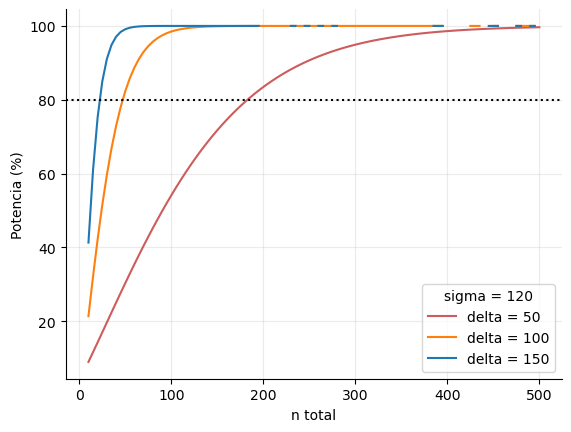

In [30]:
ns = np.arange(10, 501, 5)
for dl, c in [(50, 'indianred'), (100, 'tab:orange'), (150, 'tab:blue')]:
    plt.plot(ns, [100 * TTestIndPower().power(effect_size=dl / 120, nobs1=k / 2, alpha=.05) for k in ns], color=c, label=f'delta = {dl}')
plt.axhline(80, color='k', ls=':'); plt.xlabel('n total'); plt.ylabel('Potencia (%)'); plt.legend(title='sigma = 120'); plt.show()

Mitad de efecto o el doble de ruido requieren **cuatro veces** más muestra: $n\propto\sigma^2/\delta^2$. El análisis de potencia se hace **antes** de correr el experimento.

## 12. Ejercicios

1. **Hospital.** Agregá más controles a la regresión de la sección 1 (por ejemplo `estado` o `comuna`). ¿Cuánto cambia el coeficiente de `hosp`? ¿Se anula? ¿Por qué no podemos concluir que el hospital empeora la salud?
2. **Seis conductores.** Calculá ATE, ATT, naive y sesgo si los tratados fueran los conductores {4, 5, 6}. ¿Cambia el signo del sesgo?
3. **Simulación.** Con `simular`, verificá que en modo aleatorizado el estimador es insesgado para $\delta=100$ con $\gamma=0,1,3$ y $n=100$. ¿Cómo cambia su desvío con $n$?
4. **Happiness on Tap.** Estimá el ITT sobre `conectado` y sobre `pdiasfueaescuela` agregando interacciones $T\times$ `mujerjefe`. ¿Hay efectos heterogéneos? ¿Qué problema de inferencia aparece al mirar muchos subgrupos?
5. **Fisher.** Rehacé la inferencia por aleatorización usando como estadístico la diferencia de *medianas*. ¿Cambia el p-valor?
6. **Potencia.** ¿Cuántos hogares se necesitarían para detectar con 80% de potencia un ITT de 5 puntos porcentuales sobre la asistencia, con el desvío observado en los controles?
7. **CUPED.** Repetí la simulación de la sección 10 con $R^2=0{,}2$ y $R^2=0{,}8$ y comparalo con $1/(1-R^2)$.
8. **SUTVA.** En la simulación de mercados, ¿qué pasa con la aleatorización por mercado si hay solo 20 mercados en lugar de 200?
9. **Diseño.** Elegí un programa (educativo, de salud, una función de una app) y describí unidad de aleatorización, resultado principal, tamaño de muestra y riesgos de SUTVA.